In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image


In [2]:
import os

print(os.getcwd())

c:\Users\pranav\Desktop\MRI EXPLAINABLE  AI\notebooks


In [3]:
print(os.listdir("."))

['CNN_Model.ipynb', 'exploration.ipynb']


In [4]:
print(os.path.exists("../data/raw"))

True


In [5]:
DATA_DIR = "../data/raw"

for root, dirs, files in os.walk(DATA_DIR):
    print(root, len(files))

../data/raw 0
../data/raw\Testing 0
../data/raw\Testing\glioma 400
../data/raw\Testing\meningioma 400
../data/raw\Testing\notumor 400
../data/raw\Testing\pituitary 400
../data/raw\Training 0
../data/raw\Training\glioma 1400
../data/raw\Training\meningioma 1400
../data/raw\Training\notumor 1400
../data/raw\Training\pituitary 1400


In [6]:
records = []

for split in ["Training", "Testing"]:
    
    split_path = os.path.join(DATA_DIR, split)
    
    for class_name in os.listdir(split_path):
        class_path = os.path.join(split_path, class_name)
        
        if not os.path.isdir(class_path):
            continue
        
        for filename in os.listdir(class_path):
            
            if filename.lower().endswith((".jpg", ".jpeg", ".png")):
                
                image_path = os.path.join(
                    class_path,
                    filename
                )
                
                records.append({
                    "split": split,
                    "class": class_name,
                    "filename": filename,
                    "path": image_path
                })

df = pd.DataFrame(records)

df.head()

,split,class,filename,path
0,Training,glioma,Tr-gl_1.jpg,../data/raw\Training\glioma\Tr-gl_1.jpg
1,Training,glioma,Tr-gl_10.jpg,../data/raw\Training\glioma\Tr-gl_10.jpg
2,Training,glioma,Tr-gl_100.jpg,../data/raw\Training\glioma\Tr-gl_100.jpg
3,Training,glioma,Tr-gl_1000.jpg,../data/raw\Training\glioma\Tr-gl_1000.jpg
4,Training,glioma,Tr-gl_1001.jpg,../data/raw\Training\glioma\Tr-gl_1001.jpg


In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7200 entries, 0 to 7199
Data columns (total 4 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   split     7200 non-null   object
 1   class     7200 non-null   object
 2   filename  7200 non-null   object
 3   path      7200 non-null   object
dtypes: object(4)
memory usage: 225.1+ KB


In [8]:

from pathlib import Path
import os

# Check current notebook location
print("Current Working Directory:")
print(os.getcwd())

# Check dataset folders
DATA_DIR = Path("../data/raw")

print("\nDataset directory exists:", DATA_DIR.exists())

if DATA_DIR.exists():
    for folder in sorted(DATA_DIR.iterdir()):
        if folder.is_dir():
            print(f"\n{folder.name}/")

            for class_folder in sorted(folder.iterdir()):
                if class_folder.is_dir():
                    image_count = sum(
                        1 for file in class_folder.iterdir()
                        if file.is_file()
                    )
                    print(f"  {class_folder.name}: {image_count} files")


Current Working Directory:
c:\Users\pranav\Desktop\MRI EXPLAINABLE  AI\notebooks

Dataset directory exists: True

Testing/
  glioma: 400 files
  meningioma: 400 files
  notumor: 400 files
  pituitary: 400 files

Training/
  glioma: 1400 files
  meningioma: 1400 files
  notumor: 1400 files
  pituitary: 1400 files


pytorch installation

In [9]:

import torch
import torchvision

print("PyTorch version:", torch.__version__)
print("Torchvision version:", torchvision.__version__)

# Check available computing device
if torch.cuda.is_available():
    device = torch.device("cuda")
    print("GPU Available:", torch.cuda.get_device_name(0))
else:
    device = torch.device("cpu")
    print("GPU not available. Using CPU.")

print("Selected device:", device)


PyTorch version: 2.15.0+cpu
Torchvision version: 0.29.2+cpu
GPU not available. Using CPU.
Selected device: cpu


In [10]:
import sys

print("Notebook Python executable:")
print(sys.executable)

print("\nPython version:")
print(sys.version)


Notebook Python executable:
c:\Users\pranav\anaconda3\python.exe

Python version:
3.12.7 | packaged by Anaconda, Inc. | (main, Oct  4 2024, 13:17:27) [MSC v.1929 64 bit (AMD64)]


importing all necessary library 

In [11]:
import os
import matplotlib.pyplot as plt
import numpy as np

from pathlib import Path
from torchvision import datasets, transforms
from torch.utils.data import DataLoader, Subset
from sklearn.model_selection import train_test_split

In [12]:
DATA_DIR = Path("../data/raw")

TRAIN_DIR = DATA_DIR / "Training"
TEST_DIR = DATA_DIR / "Testing"

print("Training directory exists:", TRAIN_DIR.exists())
print("Testing directory exists:", TEST_DIR.exists())

Training directory exists: True
Testing directory exists: True


image processing 

In [13]:
IMAGE_SIZE = 224

train_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.5, 0.5, 0.5],
        std=[0.5, 0.5, 0.5]
    )
])

test_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.5, 0.5, 0.5],
        std=[0.5, 0.5, 0.5]
    )
])

loading the training dataset

In [14]:
train_dataset = datasets.ImageFolder(
    root=TRAIN_DIR,
    transform=train_transform
)

print("Total training images:", len(train_dataset))
print("Classes:", train_dataset.classes)
print("Class mapping:", train_dataset.class_to_idx)

Total training images: 5600
Classes: ['glioma', 'meningioma', 'notumor', 'pituitary']
Class mapping: {'glioma': 0, 'meningioma': 1, 'notumor': 2, 'pituitary': 3}


training and validation split 

In [15]:
labels = train_dataset.targets

indices = np.arange(len(train_dataset))

train_indices, val_indices = train_test_split(
    indices,
    test_size=0.20,
    random_state=42,
    stratify=labels
)

print("Training samples:", len(train_indices))
print("Validation samples:", len(val_indices))

Training samples: 4480
Validation samples: 1120


In [16]:
train_dataset = datasets.ImageFolder(
    root=TRAIN_DIR,
    transform=train_transform
)

val_dataset = datasets.ImageFolder(
    root=TRAIN_DIR,
    transform=test_transform
)

train_subset = Subset(train_dataset, train_indices)
val_subset = Subset(val_dataset, val_indices)

loading the testing data


In [17]:
test_dataset = datasets.ImageFolder(
    root=TEST_DIR,
    transform=test_transform
)

print("Testing samples:", len(test_dataset))

Testing samples: 1600


creating data loader

In [18]:
BATCH_SIZE = 16

train_loader = DataLoader(
    train_subset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0
)

val_loader = DataLoader(
    val_subset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Testing batches:", len(test_loader))

Training batches: 280
Validation batches: 70
Testing batches: 100


Visualize preprocessed MRI images

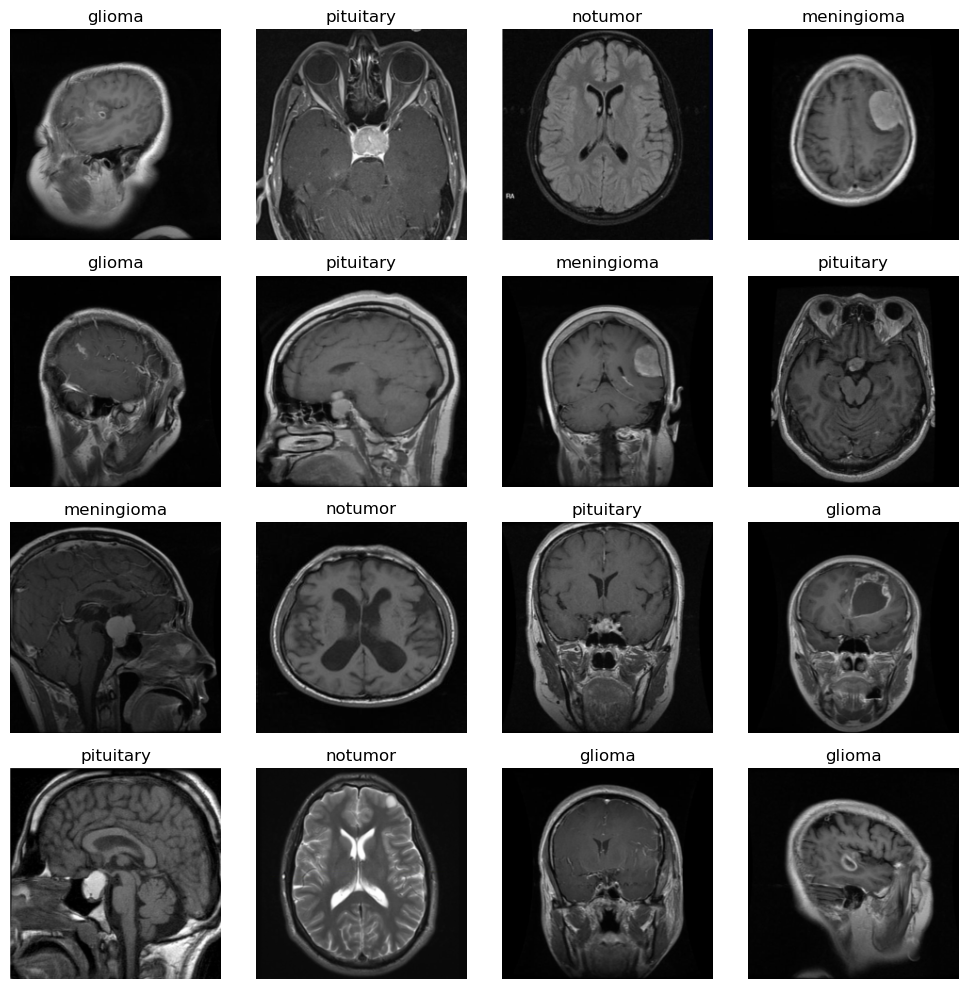

In [19]:
images, labels = next(iter(train_loader))

class_names = train_dataset.classes

fig, axes = plt.subplots(4, 4, figsize=(10, 10))

for i, ax in enumerate(axes.flat):
    image = images[i].permute(1, 2, 0).numpy()

    # Reverse normalization for visualization
    image = (image * 0.5) + 0.5
    image = np.clip(image, 0, 1)

    ax.imshow(image)
    ax.set_title(class_names[labels[i].item()])
    ax.axis("off")

plt.tight_layout()
plt.show()